# SailGP Data Analyst Challenge — Auckland, 19 January 2025

Eight questions, one afternoon of telemetry. The notebook combines course reconstruction,
wind diagnostics, polar routing and manoeuvre modelling; reusable functions are in `sgp/`.

| # | Question | Main result and qualification |
|---|---|---|
| 1 | Compass means | 95 of 1,855 racing ten-second heading bins have an arithmetic mean more than 5° from the circular mean. |
| 2 | VMC | The XML sequence is usable, but its target positions do not match the sailed course. This analysis additionally requires measured mark positions. |
| 3 | Calibration | Upwind tack differences are 3.1–4.1°. A fleet-relative adjustment reduces the held-out difference; spatial wind structure remains a competing explanation. |
| 4 | Distance to leader | A course-ladder proxy with explicit gap handling and retained completed boats, including labelled near-line finish estimates. |
| 5 | Manoeuvre counts | A boundary-constrained grid optimum under fixed best-VMG headings. It is not the unrestricted minimum over all polar angles. |
| 6 | Tacked variables | Signed channels and windward/leeward pairs, using a trailing tack vote that resets across race/data gaps. |
| 7 | Tack model | On 107 race tacks, grouped R² is 0.55 for retrospective explanation and 0.34 for entry-only prediction. The pooled 163-tack result (0.78) includes 56 pre-start tacks. |
| 8 | Race insights | The reconstructed order favours AUS in races 5/8 and DEN in 6/7. Phase accounting uses interpolated passages and a stated distance/speed allocation convention. |

All timing is inferred from telemetry, not an independent official results feed. In particular,
near-line truncated logs are marked as estimated finishes, and missing finishes remain unknown.


## Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.metrics import mean_absolute_error, r2_score, roc_auc_score
from sklearn.model_selection import GroupKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sgp import course as crs
from sgp import data, geo, plots, race, wind
from sgp import polar as plr

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200, "display.max_columns", 40, "display.precision", 2)
plots.style()
C = plots.TEAM_COLOURS

logs = data.load_boat_logs()            # 1 Hz, UTC
marks = data.load_marks()               # measured mark positions + mark wind, 1 Hz
man = data.load_manoeuvres()            # one row per tack / gybe
straights = data.load_straight_lines()  # 10 s straight-line segments
polar = plr.Polar(data.load_polar())
courses_xml = data.load_courses()
RACES = sorted(courses_xml)

overview = logs.groupby("race").agg(boats=("BOAT", "nunique"), first=("DATETIME", "min"), last=("DATETIME", "max"), rows=("BOAT", "size"))
overview["start"] = [courses_xml[r].start_time for r in overview.index]
overview["started"] = logs[logs["TRK_LEG_NUM_unk"] >= 1].groupby("race")["BOAT"].nunique()
overview

,boats,first,last,rows,start,started
race,,,,,,
25011905,11,2025-01-19 02:56:08,2025-01-19 03:18:11,7092,2025-01-19 03:08:00,10
25011906,11,2025-01-19 03:18:29,2025-01-19 03:39:00,7394,2025-01-19 03:29:00,10
25011907,11,2025-01-19 03:48:00,2025-01-19 04:00:14,6766,2025-01-19 03:50:00,10
25011908,3,2025-01-19 04:12:00,2025-01-19 04:23:15,1985,2025-01-19 04:14:00,3


Four races: three fleet races (`25011905`–`07`) and the three-boat final (`25011908`).
Canada is in the logs but never starts. All timestamps are UTC; the XML start times carry a +13:00 offset and are converted.

## Question 1 — mean of a compass direction at a lower frequency

Averaging degrees breaks at north: the mean of 350° and 10° is 0°, not 180°. `geo.resample_direction` turns every sample into a unit
vector, sums the vectors per time bin and takes the direction of the sum. It also returns

* `r`, the length of the mean vector (1 = all samples agree, 0 = they cancel). A 10 s "mean heading" through a tack has a low `r` and should not be trusted, which `min_r` enforces;
* `std`, the circular standard deviation, and `n`, the number of samples, so gaps are visible instead of silently averaged over.

Bins are real time bins (`resample`), not a rolling window, so the output really is at the lower frequency. Passing `weights` (e.g. wind speed) gives a true vector average.

In [2]:
demo = pd.Series([350.0, 355.0, 0.0, 5.0, 10.0], index=pd.date_range("2025-01-19 03:00", periods=5, freq="1s"))
print(f"plain mean: {demo.mean():.0f} deg   circular mean: {round(geo.resample_direction(demo, '10s')['mean'].iloc[0]) % 360} deg")

racing = logs[logs["TRK_LEG_NUM_unk"] >= 1].set_index("DATETIME")
rows = []
for (boat, rid), g in racing.groupby(["BOAT", "race"]):
    circ = geo.resample_direction(g["HEADING_deg"], "10s")
    naive = g["HEADING_deg"].resample("10s").mean()
    err = np.abs(geo.wrap180(naive - circ["mean"]))
    beat = g["TRK_LEG_NUM_unk"].resample("10s").median().isin([3, 5])
    rows.append({"bins": circ["mean"].notna().sum(), "wrong_by_5deg": (err > 5).sum(), "wrong_by_30deg": (err > 30).sum(), "on_a_beat": ((err > 5) & beat).sum()})
q1 = pd.DataFrame(rows).sum()
print(f"heading, all boats and races: {int(q1['wrong_by_5deg'])} of {int(q1['bins'])} ten-second bins ({q1['wrong_by_5deg'] / q1['bins']:.0%}) "
      f"have a plain mean more than 5 deg away from the circular mean;\n{int(q1['wrong_by_30deg'])} of those are more than 30 deg off, "
      f"{int(q1['on_a_beat'])} are on a beat (legs 3 and 5), where port tack is sailed close to north")

plain mean: 144 deg   circular mean: 0 deg


heading, all boats and races: 95 of 1855 ten-second bins (5%) have a plain mean more than 5 deg away from the circular mean;
84 of those are more than 30 deg off, 68 are on a beat (legs 3 and 5), where port tack is sailed close to north


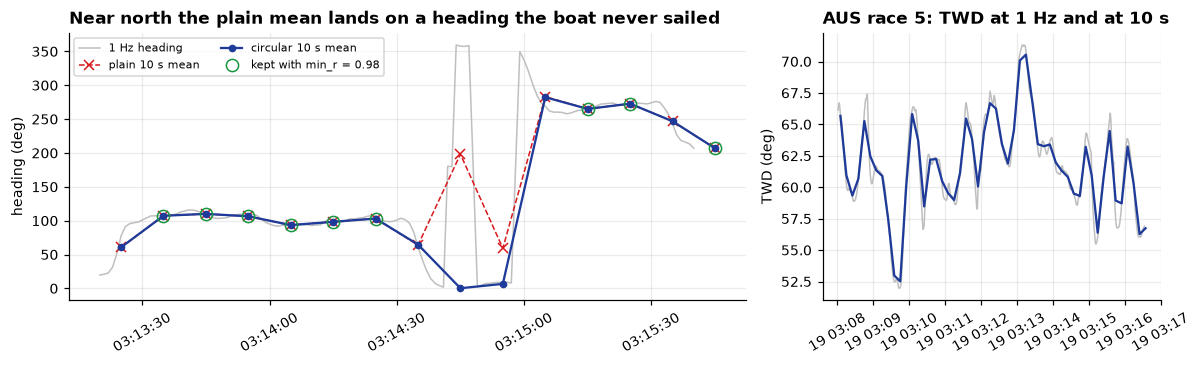

In [3]:
g = racing[(racing["BOAT"] == "AUS") & (racing["race"] == 25011905)]
win = g.loc["2025-01-19 03:13:20":"2025-01-19 03:15:40"]
circ = geo.resample_direction(win["HEADING_deg"], "10s")
steady = geo.resample_direction(win["HEADING_deg"], "10s", min_r=0.98)
naive = win["HEADING_deg"].resample("10s").mean()
mid = circ.index + pd.Timedelta("5s")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [2, 1]})
ax = axes[0]
ax.plot(win.index, win["HEADING_deg"], color="0.75", lw=1, label="1 Hz heading")
ax.plot(mid, naive, "x--", color="#d7191c", lw=1, label="plain 10 s mean")
ax.plot(mid, circ["mean"], "o-", color="#1f3b99", ms=4, label="circular 10 s mean")
ax.plot(mid, steady["mean"], "o", color="#1a9641", ms=8, mfc="none", label="kept with min_r = 0.98")
ax.set_title("Near north the plain mean lands on a heading the boat never sailed")
ax.set_ylabel("heading (deg)")
ax.legend(fontsize=7, ncol=2)
ax = axes[1]
twd = geo.resample_direction(g["TWD_SGP_deg"], "10s")
ax.plot(g.index, g["TWD_SGP_deg"], color="0.75", lw=1)
ax.plot(twd.index + pd.Timedelta("5s"), twd["mean"], color="#1f3b99", lw=1.5)
ax.set_title("AUS race 5: TWD at 1 Hz and at 10 s")
ax.set_ylabel("TWD (deg)")
for a in axes:
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()

## Question 2 — VMC from course geometry and positions

VMC is velocity projected towards the next target. Velocity comes from central differences of
lat/lon in a local metric frame with a three-sample centred smoother. The XML supplies the
waypoint sequence and rounding instructions. Passage times are interpolated within observed
position intervals; start/finish use their finite segments, while intermediate gates allow a
15 m position/antenna tolerance. Single marks use a directed rounding ray respecting Port/Stbd.
This is a geometric estimator, not a racing-rules decision system.

For gates the target is the closest point of the gate segment. Passage through a gap longer
than five seconds is not inferred. First check whether the XML targets describe the sailed course:


In [4]:
rows = []
for rid in RACES:
    c = courses_xml[rid]
    at_gun = crs.measured_marks(marks, c.start_time - pd.Timedelta("10s"), c.start_time + pd.Timedelta("10s"))
    in_race = crs.measured_marks(marks, c.start_time + pd.Timedelta("2min"), c.start_time + pd.Timedelta("8min"))
    for wp in c.waypoints:
        for name, xy in zip(wp.mark_names, wp.xy):
            rows.append({"race": rid, "mark": name, "at the gun": np.linalg.norm(c.frame.to_xy(*at_gun[name]) - xy), "mid race": np.linalg.norm(c.frame.to_xy(*in_race[name]) - xy)})
offsets = pd.DataFrame(rows).drop_duplicates(["race", "mark"]).set_index(["mark", "race"]).unstack("race").round(0)
print("Distance between the XML target and the measured mark position (m)")
offsets

Distance between the XML target and the measured mark position (m)


at the gun                            mid race                           
race   25011905 25011906 25011907 25011908 25011905 25011906 25011907 25011908
mark                                                                          
FL1       205.0      6.0      5.0    143.0      3.0      5.0      5.0    144.0
FL2       195.0     97.0     97.0    175.0    167.0     97.0     98.0    175.0
LG1        72.0     88.0    109.0    550.0     79.0     91.0    110.0    550.0
LG2         7.0      6.0      7.0    753.0      6.0      6.0      6.0    756.0
M1          6.0      6.0      3.0    685.0      6.0      6.0      5.0    686.0
SL1       214.0    206.0    204.0    176.0      6.0      5.0      4.0      4.0
SL2       190.0    188.0    182.0    357.0     24.0      5.0      4.0      3.0
WG1       131.0     46.0      5.0    712.0      5.0      6.0      5.0    712.0
WG2       147.0     42.0      5.0    783.0      6.0      6.0      5.0    785.0

The fleet-race start targets are about 180–215 m from the measured marks at the gun.
LG1 differs by roughly 75–110 m during gate use; LG2 is much closer. The final's turning-mark
targets differ by 550–790 m. Its sequence is still useful, but its target positions are unsuitable.

XML `CreationTimeDate` is 359, 377 and 398 seconds after the fleet starts, and 577 seconds after
the final start. This supports a later-export interpretation; it does not establish how or when
individual target coordinates were updated. The measured mark tracks, rather than that assumption,
are the basis of the reconstruction below.

**Additional input required here:** `as_raced_course` uses measured mark telemetry to freeze
each waypoint over the fleet-passage window. The XML-only detector leaves every boat on leg 0
in these four races; it must not be used silently as a less accurate fallback.


In [5]:
tracks = {rid: {b: g for b, g in logs[logs["race"] == rid].groupby("BOAT")} for rid in RACES}
courses = {rid: crs.as_raced_course(courses_xml[rid], marks, tracks[rid]) for rid in RACES}
metrics = {rid: race.race_tracks(logs, courses[rid]) for rid in RACES}   # logs + leg, progress, VMC

course = courses[25011905]
course.leg_table().round(0)

,from,to,bearing_deg,length_m
leg,,,,
1,SL1,M1,327.0,466.0
2,M1,LG1,244.0,1069.0
3,LG1,WG1,68.0,1253.0
4,WG1,LG1,248.0,1256.0
5,LG1,WG1,68.0,1255.0
6,WG1,LG1,242.0,1170.0
7,LG1,FL1,118.0,270.0


### Compare geometric passages with the logged leg counter

`TRK_LEG_NUM_unk` is not an input to the course reconstruction. The comparison below covers
transitions available in both series; unavailable transitions and finish estimates need separate
inspection. A timing difference need not imply either definition is a legal rounding time.


In [6]:
rows = []
for rid in RACES:
    for boat, m in metrics[rid].groupby("BOAT"):
        for k in range(1, courses[rid].n_legs + 1):
            mine, theirs = m.loc[m["leg"] >= k, "DATETIME"].min(), m.loc[m["TRK_LEG_NUM_unk"] >= k, "DATETIME"].min()
            if pd.notna(mine) and pd.notna(theirs):
                wp = courses[rid].waypoints[k - 1]
                rows.append({"waypoint": f"{k - 1} {wp.name}", "kind": "line / gate" if wp.is_gate else "single mark", "dt": (mine - theirs).total_seconds()})
check = pd.DataFrame(rows)
print(f"{len(check)} leg changes compared, {check['dt'].abs().le(10).mean():.0%} within 10 s")
check.groupby(["waypoint", "kind"])["dt"].agg(n="size", median_s="median", worst_s=lambda s: s.loc[s.abs().idxmax()]).T

227 leg changes compared, 97% within 10 s


waypoint,0 SL1,1 M1,2 LG1,3 WG1,4 LG1,5 WG1,6 LG1
kind,line / gate,single mark,line / gate,line / gate,line / gate,line / gate,single mark
n,33.0,33.0,33.0,32.0,32.0,32.0,32.0
median_s,0.0,-2.0,-3.0,-5.0,-2.0,-5.0,-1.0
worst_s,-1.0,-5.0,-19.0,-11.0,-12.0,-11.0,-8.0


The comparison reports the sample-label differences, while race durations below use the
interpolated passage times. Gate tolerance, antenna position and the logged counter's update
definition can all contribute to disagreement. These timings are suitable for a documented
VMC estimate; the comparison alone does not prove an earlier switch is more correct.

### The VMC column


In [7]:
aus = metrics[25011905].query("BOAT == 'AUS'")
aus.loc[aus["leg"] >= 1, ["DATETIME", "leg", "sog_kmh", "cog_deg", "brg_target_deg", "dist_target_m", "vmc_kmh"]].iloc[::45].head(8).set_index("DATETIME").round(1)

,leg,sog_kmh,cog_deg,brg_target_deg,dist_target_m,vmc_kmh
DATETIME,,,,,,
2025-01-19 03:08:01,1,78.1,340.4,322.4,472.7,74.3
2025-01-19 03:08:46,2,67.6,272.2,230.4,656.6,50.4
2025-01-19 03:09:32,3,57.3,96.4,62.6,1186.4,47.6
2025-01-19 03:10:18,3,50.4,14.0,45.7,702.7,42.9
2025-01-19 03:11:03,3,41.7,104.0,96.3,216.0,41.3
2025-01-19 03:11:49,4,54.4,213.6,264.8,1000.1,34.1
2025-01-19 03:12:34,4,75.9,265.1,244.6,373.5,71.1
2025-01-19 03:13:19,5,60.4,19.1,84.3,1058.0,25.4


speed from positions vs logged GPS SOG: median difference 0.5 km/h


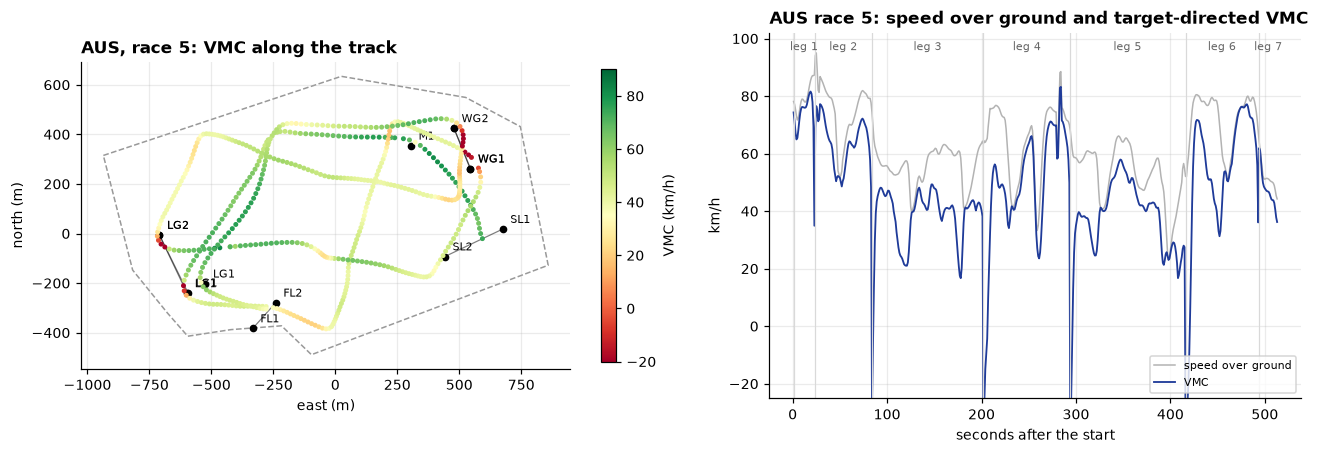

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [1.15, 1]})
ax = plots.plot_course(axes[0], course)
r = aus[aus["leg"].between(1, 7)]
sc = ax.scatter(r["x_m"], r["y_m"], c=r["vmc_kmh"], cmap="RdYlGn", vmin=-20, vmax=90, s=5, zorder=4)
plt.colorbar(sc, ax=ax, label="VMC (km/h)", shrink=0.8)
ax.set_title("AUS, race 5: VMC along the track")

ax = axes[1]
t = (r["DATETIME"] - course.start_time).dt.total_seconds()
ax.plot(t, r["sog_kmh"], color="0.7", lw=1, label="speed over ground")
ax.plot(t, r["vmc_kmh"], color="#1f3b99", lw=1.2, label="VMC")
for k in range(1, 8):
    seg = t[r["leg"] == k]
    ax.axvline(seg.iloc[0], color="0.85", lw=0.8)
    ax.text(seg.mean(), 96, f"leg {k}", ha="center", fontsize=7, color="0.4")
ax.set_ylim(-25, 102)
ax.set_xlabel("seconds after the start")
ax.set_ylabel("km/h")
ax.set_title("AUS race 5: speed over ground and target-directed VMC")
ax.legend(fontsize=7, loc="lower right")
plt.tight_layout()

err = (metrics[25011905]["sog_kmh"] - metrics[25011905]["GPS_SOG_km_h_1"]).abs()
print(f"speed from positions vs logged GPS SOG: median difference {err.median():.1f} km/h")

## Question 3 — wind diagnostics and a relative adjustment

There is no independent masthead wind truth in the supplied data. Two useful diagnostics are
port/starboard differences and leave-one-boat-out fleet differences at the same second.
Neither is an invariant: boats on different tacks can sample different positions, times, wakes
and wind gradients. Similar tack differences on a held-out race may repeat those conditions.

The proposal below is therefore **fleet-relative harmonisation under an exchangeability
assumption**, not a uniquely identified absolute sensor correction. Only steady racing samples
above 30 km/h and below 3°/s yaw are used. The reference counts distinct finite other boats.


In [9]:
L = logs[logs["BOAT"] != "CAN"].copy()
closure = pd.Series(geo.wrap180(L["TWD_SGP_deg"] - L["HEADING_deg"] - L["TWA_SGP_deg"]), index=L.index)
awa_from_true, _ = wind.apparent_from_true(L["TWA_SGP_deg"], L["TWS_SGP_km_h_1"], L["BOAT_SPEED_km_h_1"])
steady = wind.steady_sailing(L)
awa_closure = pd.Series(geo.wrap180(awa_from_true - L["AWA_SGP_deg"]), index=L.index)
print(f"TWD - HEADING - TWA      : median {closure[steady].median():+.2f} deg, IQR {closure[steady].quantile(.75) - closure[steady].quantile(.25):.1f} deg  -> on average TWD = heading + TWA; the logged TWD is the smoother of the two")
print(f"AWA rebuilt from TWA, TWS, boat speed vs logged AWA: sd {awa_closure[steady].std():.1f} deg  -> the wind triangle uses boat speed along the heading")

s = straights[(straights["TRK_LEG_NUM_unk"] >= 1) & straights["MODE"].notna()]
sensors = pd.DataFrame({
    "TWS bow / masthead": (s["TWS_BOW_SGP_km_h_1"] / s["TWS_MHU_SGP_km_h_1"]).groupby(s["BOAT"]).median(),
    "TWD bow - masthead (deg)": pd.Series(geo.wrap180(s["TWD_BOW_SGP_deg"] - s["TWD_MHU_SGP_deg"]), index=s.index).groupby(s["BOAT"]).median(),
    "TWD SGP - masthead (deg)": pd.Series(geo.wrap180(s["TWD_SGP_deg"] - s["TWD_MHU_SGP_deg"]), index=s.index).groupby(s["BOAT"]).median(),
})
rh = L[steady & (L["BOAT_SPEED_km_h_1"] > 50)].groupby("BOAT")[["LENGTH_RH_P_mm", "LENGTH_RH_S_mm", "LENGTH_RH_BOW_mm"]].median()
pd.concat([sensors, rh], axis=1).round(2).T

TWD - HEADING - TWA      : median -0.08 deg, IQR 7.3 deg  -> on average TWD = heading + TWA; the logged TWD is the smoother of the two
AWA rebuilt from TWA, TWS, boat speed vs logged AWA: sd 1.3 deg  -> the wind triangle uses boat speed along the heading


BOAT,AUS,BRA,DEN,ESP,GBR,GER,ITA,NZL,SUI,USA
TWS bow / masthead,0.98,0.97,0.97,0.99,0.97,0.95,0.94,1.00,0.93,0.70
TWD bow - masthead (deg),0.95,0.05,0.92,0.95,-0.35,0.34,1.83,-0.32,0.55,18.66
TWD SGP - masthead (deg),0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
LENGTH_RH_P_mm,995.05,1012.90,966.20,975.65,995.72,917.67,1061.82,946.15,987.58,874.79
LENGTH_RH_S_mm,994.24,947.99,941.36,974.66,972.70,908.28,1080.16,960.64,986.50,-801.86
LENGTH_RH_BOW_mm,983.49,1032.60,885.06,964.87,946.18,871.90,980.92,916.38,933.78,831.68


The displayed **median** direction difference between SGP and masthead channels is zero
for each boat; that summary does not by itself establish elementwise identity or source selection.
USA's bow speed/direction differ substantially from the masthead and are treated as suspect,
without claiming the physical fault mechanism is known.

USA's starboard ride-height channel is persistently implausible near −800 mm. Race summaries
explicitly exclude it before taking the median of remaining channels. Foiling thresholds and
aggregation remain operational choices rather than independently validated flight-state truth.

### 3.2 Fleet-wide tack differences


In [10]:
S = L[steady].copy()
S["TWD_inst"] = wind.instantaneous_twd(S)          # heading + TWA, unfiltered
fleet = S[S["race"] != 25011908]                   # the final has 3 boats: too few for a fleet reference
flip = wind.tack_flip(fleet, "TWD_inst").drop("reach", level="sail")
flip.round(2)

flip_deg  tws_ratio  n_port  n_stbd
race     sail                                         
25011905 downwind      0.33       1.07     728     768
         upwind       -4.08       1.02    1054     916
25011906 downwind     -0.11       1.02     795     733
         upwind       -3.12       1.02    1051    1039
25011907 downwind     -0.96       1.07     721     750
         upwind       -3.14       1.00    1057     909

The upwind direction difference is about −3 to −4° in each fleet race; downwind it stays
within 1°. If environmental sampling and heading errors could be excluded, a symmetric half-flip
correction would narrow absolute TWA by about 1.8°. They cannot be excluded here. Masthead
flow distortion, apparent-speed calibration and real spatial wind structure are hypotheses,
not diagnoses established by this difference.

The logged leeway sign is consistent with course-through-water = heading − leeway. The following
reconstruction shows that applying the logged correction increases the observed upwind difference.
It tests that particular correction, rather than ruling out every leeway/current/heading explanation.


In [11]:
awa, aws = wind.apparent_from_true(fleet["TWA_SGP_deg"], fleet["TWS_SGP_km_h_1"], fleet["BOAT_SPEED_km_h_1"])
apparent = aws.to_numpy()[:, None] * geo.unit_from_bearing(fleet["HEADING_deg"] + awa)      # 'from' vector, earth frame
rows = {}
for label, direction, speed in [("as logged: boat speed along heading", fleet["HEADING_deg"], fleet["BOAT_SPEED_km_h_1"]),
                                ("with leeway: course through water", fleet["HEADING_deg"] - fleet["LEEWAY_deg"], fleet["BOAT_SPEED_km_h_1"]),
                                ("over ground: GPS COG and SOG", fleet["GPS_COG_deg"], fleet["GPS_SOG_km_h_1"])]:
    true = apparent - speed.to_numpy()[:, None] * geo.unit_from_bearing(direction)
    f = wind.tack_flip(fleet.assign(_twd=geo.bearing_of(true), _tws=np.linalg.norm(true, axis=1), _all=0), "_twd", "_tws", by=("_all",)).droplevel(0)
    rows[label] = {"upwind flip (deg)": f.loc["upwind", "flip_deg"], "downwind flip (deg)": f.loc["downwind", "flip_deg"]}
pd.DataFrame(rows).T.round(2)

,upwind flip (deg),downwind flip (deg)
as logged: boat speed along heading,-3.51,-0.20
with leeway: course through water,-5.98,0.09
over ground: GPS COG and SOG,-6.04,0.01


### 3.3 Boat by boat, against the rest of the fleet

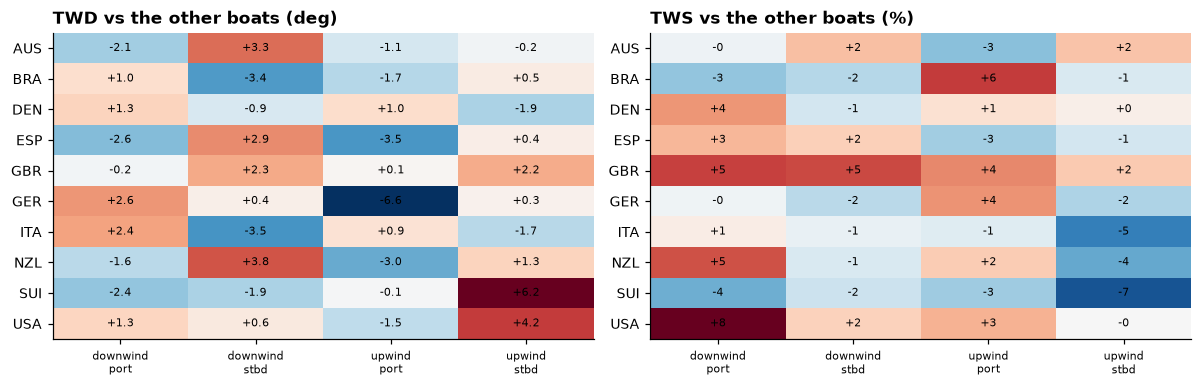

In [12]:
res = wind.calibration_residuals(fleet, "TWD_inst", "TWS_SGP_km_h_1")
res = res[res["sail"] != "reach"]
cells = res.groupby(["BOAT", "sail", "tack"]).agg(d=("d_twd", "mean"), r=("r_tws", "mean"))
d_twd = cells["d"].unstack(["sail", "tack"])
r_tws = (100 * (cells["r"] - 1)).unstack(["sail", "tack"])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, tab, title, lim, unit in [(axes[0], d_twd, "TWD vs the other boats (deg)", 6, "{:+.1f}"), (axes[1], r_tws, "TWS vs the other boats (%)", 8, "{:+.0f}")]:
    im = ax.imshow(tab.to_numpy(), cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
    ax.set_xticks(range(tab.shape[1]), [f"{a}\n{b}" for a, b in tab.columns], fontsize=7)
    ax.set_yticks(range(tab.shape[0]), tab.index)
    for (i, j), v in np.ndenumerate(tab.to_numpy()):
        ax.text(j, i, unit.format(v), ha="center", va="center", fontsize=7)
    ax.set_title(title)
    ax.grid(False)
plt.tight_layout()

A common residual sign on both tacks is compatible with alignment error, and opposite signs
are compatible with a TWA magnitude error. Speed differences can reflect calibration or conditions.
The table identifies candidates for investigation, not unique fault diagnoses.

### 3.4 Proposed relative correction and held-out comparison

`fit_calibration` subtracts a tack-dependent half-flip and a shrunken boat offset, and divides
TWS by a relative speed factor. It is fitted on races 5/6 and evaluated on race 7. Reducing
the held-out discrepancy demonstrates same-day transfer under similar sampling; it does not
establish an absolute calibration or remove common fleet errors.


In [13]:
train, test = fleet[fleet["race"] != 25011907], fleet[fleet["race"] == 25011907]
table_train = wind.fit_calibration(train)


def spread(df, twd, tws):
    r = wind.calibration_residuals(df, twd, tws)
    cell = r[r["sail"] != "reach"].groupby(["BOAT", "sail", "tack"]).agg(d=("d_twd", "mean"), s=("r_tws", "mean"), n=("d_twd", "size")).query("n >= 30")
    f = wind.tack_flip(df, twd, tws)["flip_deg"].groupby("sail").mean()
    return {"upwind flip (deg)": f["upwind"], "downwind flip (deg)": f["downwind"], "boat-cell TWD rms (deg)": np.sqrt((cell["d"] ** 2).mean()), "boat-cell TWS rms (%)": 100 * np.sqrt(((cell["s"] - 1) ** 2).mean())}


rows = {}
for label, df in [("races 5+6 (fitted)", train), ("race 7 (held out)", test)]:
    cal = wind.apply_calibration(df, table_train)
    rows[(label, "logged")] = spread(df, "TWD_inst", "TWS_SGP_km_h_1")
    rows[(label, "calibrated")] = spread(cal, "TWD_cal_deg", "TWS_cal_km_h_1")
pd.DataFrame(rows).T.round(2)

upwind flip (deg)  downwind flip (deg)  boat-cell TWD rms (deg)  boat-cell TWS rms (%)
races 5+6 (fitted) logged                  -3.60                 0.11                     2.49                   3.61
                   calibrated              -0.27                 0.39                     0.57                   1.15
race 7 (held out)  logged                  -3.14                -0.96                     3.21                   4.10
                   calibrated               0.22                -0.81                     2.26                   3.58

On race 7 the upwind difference changes from −3.14° to +0.22°, and between-boat residual
RMS decreases. The table above reports the full direction and speed diagnostics. A spatially
structured wind pattern recurring across these races could also transfer, so validation on other
days/course orientations and controlled reciprocal runs would be needed to identify sensor errors.

The next table fits all three fleet races and generates proposed adjusted channels.


In [14]:
calibration = wind.fit_calibration(fleet)
logs_cal = wind.apply_calibration(L, calibration)   # adds TWA_cal_deg, TWD_cal_deg, TWS_cal_km_h_1 to every row
show = calibration.drop("reach", level="sail")
pd.concat({"TWA correction to subtract (deg)": show["dtwa_deg"].unstack(["sail", "tack"]), "TWS divisor": show["tws_factor"].unstack(["sail", "tack"])}, axis=1).round(2)

TWA correction to subtract (deg)                    TWS divisor                   
sail                         downwind       upwind          downwind       upwind      
tack                             port  stbd   port  stbd        port  stbd   port  stbd
BOAT                                                                                   
AUS                             -1.48  2.37  -1.10  1.66        1.00  1.02   0.97  1.02
BRA                              0.73 -2.49  -2.00  0.80        0.97  0.98   1.04  0.99
DEN                              0.87 -0.67   0.35 -0.99        1.03  0.99   1.01  1.00
ESP                             -2.04  2.32  -3.31  0.79        1.02  1.01   0.98  0.99
GBR                             -0.13  1.85  -0.32  2.27        1.04  1.04   1.03  1.02
GER                              1.94  0.37  -6.01  0.63        1.00  0.98   1.03  0.98
ITA                              1.73 -2.49   0.00 -0.72        1.00  1.00   0.99  0.95
NZL                             -1.33  3.05  -2.87  1.36        1.04  0.99   1.02  0.97
SUI                             -1.74 -1.48  -0.45  5.43        0.97  0.99   0.98  0.94
USA                              0.85  0.51  -1.76  3.82        1.06  1.01   1.02  1.00

In [15]:
mark_wind = marks[(marks["DATETIME"] >= "2025-01-19 03:08") & (marks["DATETIME"] <= "2025-01-19 04:00")].groupby("MARK").agg(
    TWD=("TWD_deg", wind.circular_mean_deg), TWD_sd=("TWD_deg", "std"), TWS=("TWS_km_h_1", "mean"))
boats_now = logs_cal[steady.reindex(logs_cal.index, fill_value=False) & (logs_cal["race"] != 25011908)]
print(f"boats, calibrated: TWD {wind.circular_mean_deg(boats_now['TWD_cal_deg']):.1f} deg, TWS {boats_now['TWS_cal_km_h_1'].mean():.1f} km/h")
mark_wind.round(1).T

boats, calibrated: TWD 62.1 deg, TWS 37.9 km/h


MARK,FL1,FL2,LG1,LG2,M1,SL1,SL2,WG1,WG2
TWD,67.1,72.2,66.6,63.7,63.4,64.6,70.0,63.5,61.5
TWD_sd,5.0,6.9,5.9,5.0,4.7,10.4,12.0,9.6,5.4
TWS,31.1,32.1,33.9,36.2,31.8,31.4,32.3,25.0,30.2


**Limits.** These are relative corrections. Low mark anemometers are spatially separated
and disagree with one another, so they do not certify the absolute boat calibration. Downwind,
port samples report more wind than starboard samples; different sides of the course may explain
part of that pattern. The same environmental caution applies to the upwind direction difference.
A controlled reciprocal calibration run in steady conditions is the appropriate next test.


## Question 4 — distance to leader

Positions become a course-ladder coordinate. Each completed leg contributes its centre-line
length; the current leg uses signed distances to its start and end reference lines to define a
normalised fraction. This is continuous at a shared gate line when those intersections are
well-defined; single-mark rounding rays remain a geometric approximation to progress.

The leader is maximum progress, including retained completed boats. Completed boats all have
zero remaining ladder gap; this is not a finish-time gap. Long missing intervals stay missing.
For logs stopping shortly before the line, a positive recent closing rate supports at most five
seconds of extrapolation, explicitly labelled estimated. Missing unfinished boats are not carried
forward. On beats, this ladder proxy does not know about future shifts, laylines or tactical cover.


In [16]:
dtl, progress, legs = crs.distance_to_leader(tracks[25011905], course)
dtl_race = dtl.loc[course.start_time:].dropna(how="all").drop(columns="CAN", errors="ignore")
dtl_race.iloc[::60].round(0)

,AUS,BRA,DEN,ESP,GBR,GER,ITA,NZL,SUI,USA
2025-01-19 03:08:01,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2025-01-19 03:09:01,0.0,223.0,128.0,125.0,85.0,212.0,146.0,180.0,258.0,266.0
2025-01-19 03:10:01,0.0,410.0,211.0,389.0,144.0,357.0,331.0,178.0,397.0,413.0
2025-01-19 03:11:01,0.0,418.0,281.0,482.0,74.0,331.0,473.0,246.0,452.0,536.0
2025-01-19 03:12:01,78.0,506.0,495.0,554.0,0.0,506.0,545.0,503.0,580.0,626.0
2025-01-19 03:13:01,119.0,791.0,344.0,594.0,0.0,371.0,515.0,580.0,919.0,906.0
2025-01-19 03:14:01,12.0,533.0,537.0,461.0,0.0,503.0,460.0,462.0,716.0,679.0
2025-01-19 03:15:01,0.0,407.0,450.0,276.0,26.0,341.0,276.0,275.0,619.0,600.0
2025-01-19 03:16:01,0.0,846.0,944.0,566.0,136.0,711.0,452.0,551.0,1006.0,997.0
2025-01-19 03:17:01,0.0,308.0,371.0,116.0,0.0,235.0,0.0,108.0,656.0,575.0


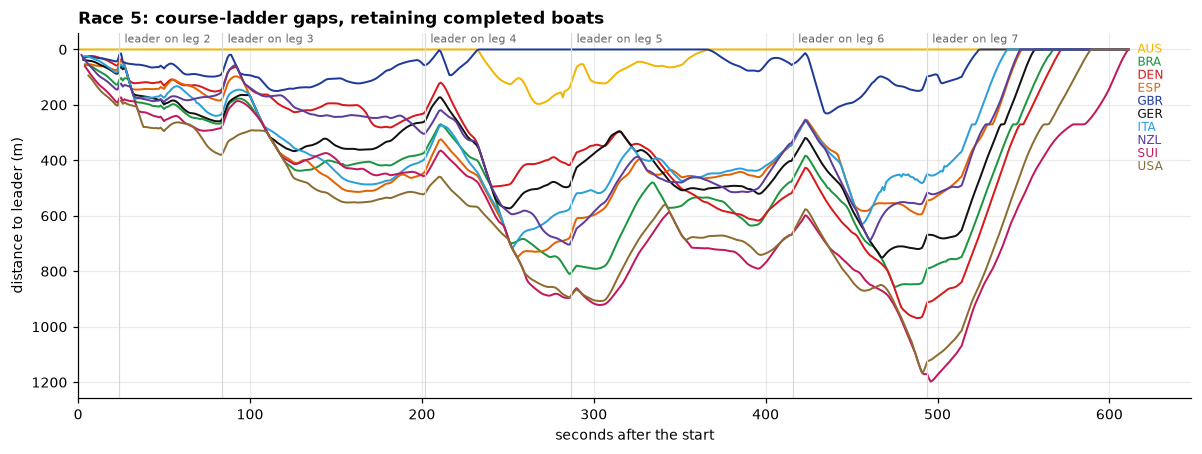

In [17]:
fig, ax = plt.subplots(figsize=(11, 4.2))
t = (dtl_race.index - course.start_time).total_seconds()
for boat in dtl_race:
    ax.plot(t, dtl_race[boat], color=C[boat], lw=1.3)
leader_leg = legs.loc[dtl_race.index].max(axis=1)
for k in range(2, 8):
    ax.axvline(t[(leader_leg >= k).to_numpy().argmax()], color="0.85", lw=0.8)
    ax.text(t[(leader_leg >= k).to_numpy().argmax()] + 3, -25, f"leader on leg {k}", fontsize=7, color="0.4")
ax.invert_yaxis()
plots.label_lines(ax, dtl_race.set_axis(t))
ax.set_xlim(0, t.max() * 1.06)
ax.set_xlabel("seconds after the start")
ax.set_ylabel("distance to leader (m)")
ax.set_title("Race 5: course-ladder gaps, retaining completed boats")
plt.tight_layout()

In [18]:
at_marks = {}
for k in range(2, 9):
    reached = leader_leg >= k
    if reached.any():
        at_marks[f"leader ends leg {k - 1}"] = dtl_race.loc[reached.idxmax()]
final_order = race.leg_times(metrics[25011905], course)[8].sort_values().index
pd.DataFrame(at_marks).reindex(final_order).round(0)

,leader ends leg 1,leader ends leg 2,leader ends leg 3,leader ends leg 4,leader ends leg 5,leader ends leg 6,leader ends leg 7
BOAT,,,,,,,
AUS,0.0,0.0,0.0,119.0,0.0,0.0,0.0
GBR,19.0,82.0,57.0,0.0,53.0,97.0,99.0
ITA,60.0,226.0,391.0,559.0,334.0,449.0,369.0
NZL,127.0,145.0,302.0,691.0,326.0,516.0,491.0
ESP,48.0,176.0,438.0,663.0,335.0,545.0,458.0
GER,68.0,249.0,256.0,476.0,392.0,668.0,652.0
BRA,108.0,258.0,367.0,804.0,465.0,790.0,749.0
DEN,39.0,139.0,224.0,407.0,508.0,912.0,839.0
USA,186.0,376.0,518.0,886.0,658.0,1125.0,1014.0


The same picture as an interactive Bokeh chart (hover for boat and distance) is written to `figures/dtl_race5.html`.

In [19]:
from pathlib import Path

from bokeh.models import HoverTool
from bokeh.plotting import figure, output_file, save

Path("figures").mkdir(exist_ok=True)
output_file("figures/dtl_race5.html", title="Distance to leader, race 5")
p = figure(width=1000, height=450, title="Distance to leader, race 5 (m)", x_axis_label="seconds after the start", y_axis_label="distance to leader (m)", y_range=(float(np.nanmax(dtl_race.to_numpy())) * 1.05, -20))
for boat in dtl_race:
    r = p.line(t, dtl_race[boat].to_numpy(), color=C[boat], line_width=2, legend_label=boat, name=boat)
p.add_tools(HoverTool(tooltips=[("boat", "$name"), ("t", "@x{0} s"), ("DTL", "@y{0} m")]))
p.legend.click_policy = "hide"
p.legend.location = "bottom_left"
_ = save(p)

## Question 5 — conditional minimum manoeuvre counts

The objective here is the fewest heading switches **under fixed best-VMG headings** for the supplied
wind/polar. A direct course between the upwind/downwind targets is a fetch. Otherwise the route is
a staircase in coordinates spanned by the two best-VMG headings. A dynamic programme minimises
turns on an n × n grid. Every full edge, including fetches and endpoints, must remain inside the
boundary with the requested clearance; narrow concavities cannot be skipped between grid nodes.

This is a restricted grid optimum, not a continuous global optimum or the minimum over every
positive-speed angle in the polar. Each previous/next gate mark combination is evaluated separately;
the first leg starts at the line midpoint. Routes end at point marks and do not model legal rounding
clearance, incoming tack continuity, manoeuvre losses, traffic or wind shifts. Turn locations are one
sampled solution, not places where turns necessarily have to occur. The margin used below is 20 m.


In [20]:
race_wind = {}
for rid in RACES:
    w = logs_cal[(logs_cal["race"] == rid) & steady.reindex(logs_cal.index, fill_value=False)]
    race_wind[rid] = (wind.circular_mean_deg(w["TWD_cal_deg"]), w["TWS_cal_km_h_1"].mean())
twd5, tws5 = race_wind[25011905]
targets = polar.targets(tws5)
print(f"race 5 wind: {twd5:.0f} deg, {tws5:.0f} km/h -> best VMG at TWA {targets['up_twa']:.0f} upwind ({targets['up_bsp']:.0f} km/h) and {targets['down_twa']:.0f} downwind ({targets['down_bsp']:.0f} km/h)")

mm = plr.course_min_manoeuvres(course, twd5, tws5, polar, margin=20)
mm.drop(columns="path").set_index(["leg", "mode", "from", "to"])["manoeuvres"].unstack("to").map(lambda v: "" if pd.isna(v) else int(v))

race 5 wind: 61 deg, 39 km/h -> best VMG at TWA 44 upwind (60 km/h) and 152 downwind (76 km/h)


to               FL1 FL2 LG1 LG2 M1 WG1 WG2
leg mode  from                             
1   fetch mid SL                  0        
2   run   M1               1   1           
3   beat  LG1                         2   2
          LG2                         1   1
4   run   WG1              1   1           
          WG2              1   1           
5   beat  LG1                         2   2
          LG2                         1   1
6   run   WG1              1               
          WG2              1               
7   fetch LG1          0

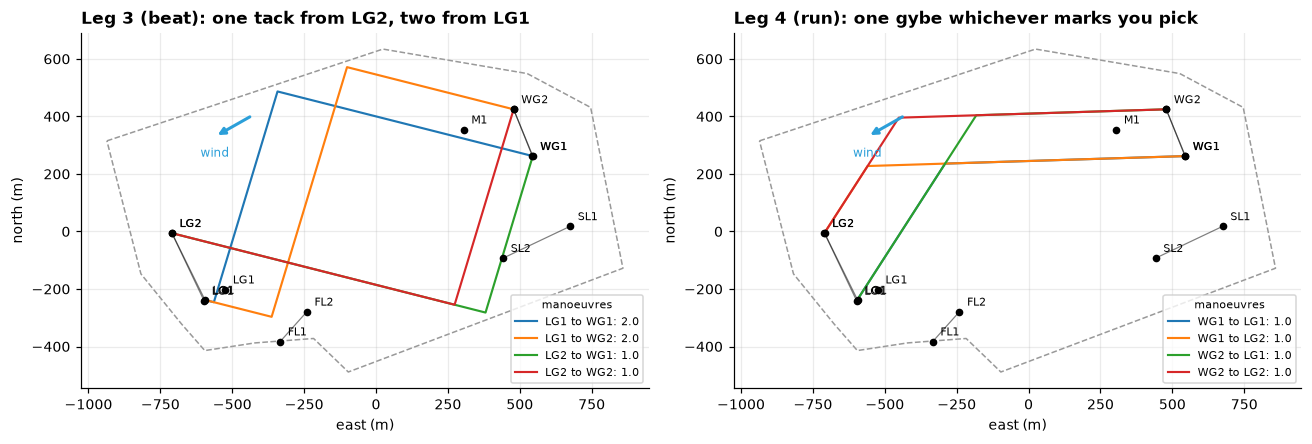

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, leg, title in [(axes[0], 3, "Leg 3 (beat): one tack from LG2, two from LG1"), (axes[1], 4, "Leg 4 (run): one gybe whichever marks you pick")]:
    plots.plot_course(ax, course)
    for i, (_, r) in enumerate(mm[mm["leg"] == leg].iterrows()):
        if r["path"] is None:
            continue
        ax.plot(r["path"][:, 0], r["path"][:, 1], lw=1.4, color=plt.cm.tab10(i), label=f"{r['from']} to {r['to']}: {r['manoeuvres']}")
    ax.annotate("", xy=(-560, 330), xytext=(-560 + 150 * np.sin(np.radians(twd5)), 330 + 150 * np.cos(np.radians(twd5))), arrowprops=dict(arrowstyle="-|>", color="#2b9fd9", lw=2))
    ax.text(-560, 260, "wind", color="#2b9fd9", fontsize=8, ha="center")
    ax.set_title(title)
    ax.legend(fontsize=7, loc="lower right", title="manoeuvres", title_fontsize=7)
plt.tight_layout()

In [22]:
rows = []
for rid in RACES:
    twd_r, tws_r = race_wind[rid]
    need = plr.course_min_manoeuvres(courses[rid], twd_r, tws_r, polar, margin=20).groupby("leg")["manoeuvres"].min()
    sailed = man[(man["race"] == rid) & man["leg"].between(1, 7)].groupby(["BOAT", "leg"]).size().unstack("leg").reindex(columns=range(1, 8)).fillna(0)
    finishers = race.leg_times(metrics[rid], courses[rid])[8].dropna().index
    sailed = sailed.reindex(finishers).fillna(0)
    for leg in range(1, 8):
        rows.append({"race": rid, "leg": leg, "minimum": need[leg], "fleet min": sailed[leg].min(), "fleet median": sailed[leg].median(), "fleet max": sailed[leg].max()})
compare = pd.DataFrame(rows).set_index(["race", "leg"])
print("Minimum from the model vs manoeuvres actually sailed (manoeuvre summary, finishers only)")
compare.unstack("race").swaplevel(axis=1).sort_index(axis=1).astype(int)

Minimum from the model vs manoeuvres actually sailed (manoeuvre summary, finishers only)


race  25011905                                 25011906                                 25011907                                 25011908                               
     fleet max fleet median fleet min minimum fleet max fleet median fleet min minimum fleet max fleet median fleet min minimum fleet max fleet median fleet min minimum
leg                                                                                                                                                                     
1            0            0         0       0         1            0         0       0         1            0         0       0         1            1         0       0
2            3            1         1       1         2            1         0       1         2            1         1       1         1            1         1       1
3            2            2         1       1         2            2         1       1         3            2         1       1         2            2         2       2
4            2            1         1       1         2            1         1       1         3            1         1       1         2            2         1       1
5            2            2         1       1         2            2         0       1         2            2         1       1         2            1         1       1
6            1            1         1       1         2            1         1       1         2            1         0       1         2            2         1       1
7            1            0         0       0         0            0         0       0         1            0         0       0         0            0         0       1

The comparison is descriptive under the fixed-heading, fixed-wind, point-mark assumptions.
Counts below the model can reflect different sailing angles, clearance choices, detection or summary
definitions; no individual exception is diagnosed without reconstructing its track. The final has
different median patterns from the fleet races. Grid refinement and heading/rounding sensitivity
should precede a tactical claim that a particular turn count is unavoidable.


## Question 6 — tacked variables

Signed channels are mirrored on port tack; port/starboard pairs become windward/leeward.
Negative TWA denotes port tack. A trailing three-second sign vote reduces flicker without using
future observations and resets across race/data gaps. This is a smoothing rule, not a three-second
hold after every tack. The steady-sailing medians below check the sign mapping for these channels.


In [23]:
tk = wind.add_tacked(L)
tk["sail"] = wind.point_of_sail(tk["TWA_SGP_deg"])
up = tk[steady & (tk["sail"] == "upwind")]
raw = up.groupby("tack")[wind.SIGNED_CHANNELS].median().T
raw["tacked port"], raw["tacked stbd"] = up[up["tack"] == "port"][[c + "_tk" for c in wind.SIGNED_CHANNELS]].median().to_numpy(), up[up["tack"] == "stbd"][[c + "_tk" for c in wind.SIGNED_CHANNELS]].median().to_numpy()
raw.columns = ["raw port", "raw stbd", "tacked port", "tacked stbd"]
raw.round(1)

,raw port,raw stbd,tacked port,tacked stbd
TWA_SGP_deg,-47.9,46.8,47.9,46.8
AWA_SGP_deg,-20.4,19.9,20.4,19.9
LEEWAY_deg,-1.5,1.7,1.5,1.7
HEEL_deg,1.0,-1.3,-1.0,-1.3
RATE_YAW_deg_s_1,-0.2,0.1,0.2,0.1
ANGLE_RUDDER_deg,-0.6,0.1,0.6,0.1
ANGLE_WING_ROT_deg,-14.4,14.3,14.4,14.3
ANGLE_WING_TWIST_deg,-29.2,28.2,29.2,28.2
ANGLE_CA1_deg,16.6,-16.7,-16.6,-16.7
ANGLE_CA2_deg,10.0,-10.4,-10.0,-10.4


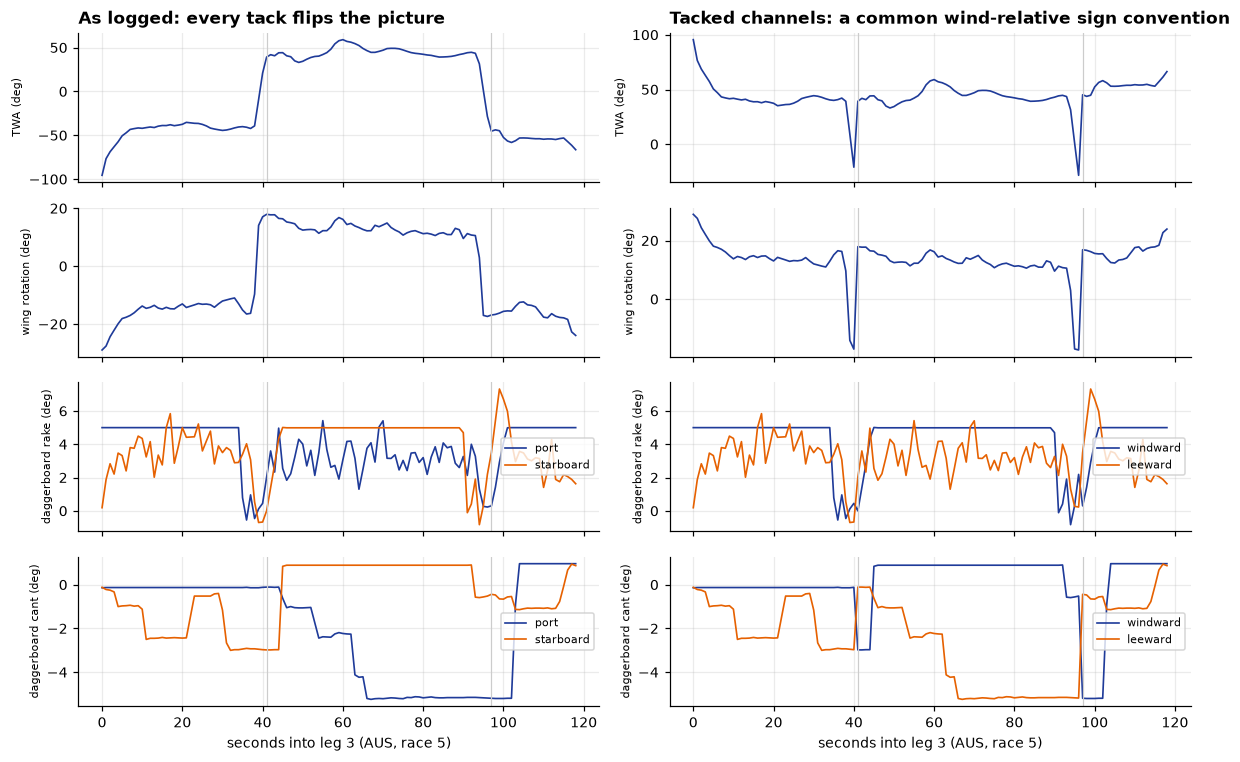

In [24]:
leg3 = tk[(tk["BOAT"] == "AUS") & (tk["race"] == 25011905) & (tk["TRK_LEG_NUM_unk"] == 3)]
t = (leg3["DATETIME"] - leg3["DATETIME"].iloc[0]).dt.total_seconds()
panels = [("TWA (deg)", ["TWA_SGP_deg"], ["TWA_SGP_deg_tk"]),
          ("wing rotation (deg)", ["ANGLE_WING_ROT_deg"], ["ANGLE_WING_ROT_deg_tk"]),
          ("daggerboard rake (deg)", ["ANGLE_DB_RAKE_P_deg", "ANGLE_DB_RAKE_S_deg"], ["ANGLE_DB_RAKE_WW_deg", "ANGLE_DB_RAKE_LW_deg"]),
          ("daggerboard cant (deg)", ["ANGLE_DB_CANT_P_deg", "ANGLE_DB_CANT_S_deg"], ["ANGLE_DB_CANT_WW_deg", "ANGLE_DB_CANT_LW_deg"])]
names = {"P": "port", "S": "starboard", "WW": "windward", "LW": "leeward"}
fig, axes = plt.subplots(len(panels), 2, figsize=(11, 7), sharex=True)
for row, (label, raw_cols, tk_cols) in enumerate(panels):
    for col, cols in enumerate([raw_cols, tk_cols]):
        ax = axes[row, col]
        for i, c in enumerate(cols):
            side = [names[p] for p in c.split("_") if p in names]
            ax.plot(t, leg3[c], lw=1.1, color=["#1f3b99", "#e66101"][i], label=side[0] if side else None)
        for tt in t[leg3["tack"] != leg3["tack"].shift()].iloc[1:]:
            ax.axvline(tt, color="0.8", lw=0.8)
        ax.set_ylabel(label, fontsize=7)
        if len(cols) > 1:
            ax.legend(fontsize=7, loc="center right")
axes[0, 0].set_title("As logged: every tack flips the picture")
axes[0, 1].set_title("Tacked channels: a common wind-relative sign convention")
axes[-1, 0].set_xlabel("seconds into leg 3 (AUS, race 5)")
axes[-1, 1].set_xlabel("seconds into leg 3 (AUS, race 5)")
plt.tight_layout()

Tack-normalised differences are useful diagnostics. They can reflect setup, but also wind,
sea state, speed or sensor differences. Matched-condition comparisons are needed to distinguish them;
USA's invalid ride-height channel is not evidence of an intentional setup asymmetry.


In [25]:
asym = up.groupby(["BOAT", "tack"])[["TWA_SGP_deg_tk", "ANGLE_WING_ROT_deg_tk", "ANGLE_WING_TWIST_deg_tk", "HEEL_deg_tk", "LENGTH_RH_LW_mm", "BOAT_SPEED_km_h_1"]].median().unstack("tack")
diff = (asym.xs("port", axis=1, level="tack") - asym.xs("stbd", axis=1, level="tack")).round(1)
diff.columns = ["TWA", "wing rotation", "wing twist", "heel", "leeward ride height (mm)", "boat speed (km/h)"]
print("Upwind, port tack minus starboard tack (tacked channels)")
diff.T

Upwind, port tack minus starboard tack (tacked channels)


BOAT,AUS,BRA,DEN,ESP,GBR,GER,ITA,NZL,SUI,USA
TWA,-3.0,7.8,0.2,3.6,-4.9,5.4,0.4,3.0,-3.9,0.4
wing rotation,-1.5,1.7,0.2,1.2,-1.2,2.0,-0.6,-2.6,0.4,0.5
wing twist,-2.0,2.6,-1.6,0.6,2.5,0.2,1.7,2.3,-0.4,5.0
heel,1.2,-0.8,0.8,0.5,-0.4,0.0,1.3,0.0,0.0,0.8
leeward ride height (mm),14.1,-123.6,0.3,-22.8,-39.4,-48.9,41.3,8.7,-51.3,-1614.7
boat speed (km/h),-2.0,2.3,-0.0,-1.0,-0.9,5.1,3.5,-0.3,0.3,-1.2


## Question 7 — race tacks and retrospective explanation

The summary has 196 tacks, of which 163 meet entry TWA <65° and exit TWA <75°.
Of these, 107 occur during racing and 56 before the start. The **main model uses the 107 race tacks**;
pre-start turns may prioritise time/position rather than maximum VMG and are a separate sensitivity.

The summary has no supplied schema. Its theoretical distances imply a 40 s window, the flying flag
matches turn_min_rh >400 mm, and loss_vs_targ_vmg equals theoretical_targ_distance − vmg_distance.
The target is a wind-dependent benchmark residual in metres, not a dimensionless normalisation or
a causal estimate of the turn's cost. A negative value means progress exceeded this benchmark over
the window; it does not prove the manoeuvre was free.


,n,loss_m,min_speed,exit_speed
foiling,,,,
came down,53,37.5,34.1,47.2
stayed on the foils,54,-7.0,39.5,51.7


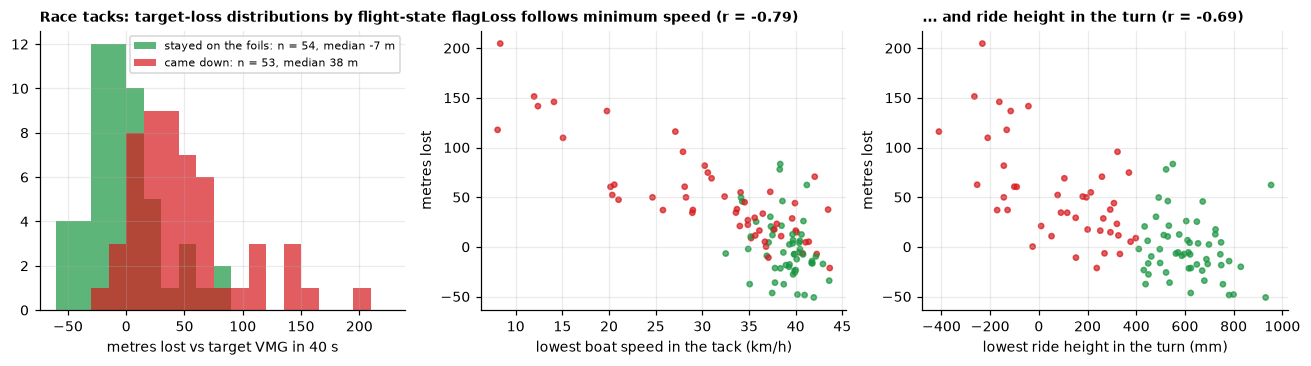

In [26]:
all_tacks = man[(man["type"] == "tack") & (man["entry_twa"] < 65) & (man["exit_twa"] < 75)].copy()
all_tacks["prestart"] = (all_tacks["leg"] == 0).astype(int)
tacks = all_tacks[all_tacks["leg"] > 0].copy()
for c in ("drop_time", "unstow_time"):
    tacks[c] = tacks[c + "_P"].fillna(tacks[c + "_S"])           # the board that was dropped
tacks["prestart"] = (tacks["leg"] == 0).astype(int)
tacks["foiling"] = tacks["flying"].map({1: "stayed on the foils", 0: "came down"})
y = tacks["loss_vs_targ_vmg"]

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
ax = axes[0]
bins = np.arange(-60, 240, 15)
for label, colour in [("stayed on the foils", "#1a9641"), ("came down", "#d7191c")]:
    part = y[tacks["foiling"] == label]
    ax.hist(part, bins=bins, alpha=0.7, color=colour, label=f"{label}: n = {len(part)}, median {part.median():.0f} m")
ax.set_xlabel("metres lost vs target VMG in 40 s")
ax.set_title("Race tacks: target-loss distributions by flight-state flag", fontsize=9)
ax.legend(fontsize=7)
for ax, col, label in [(axes[1], "min_bsp", "lowest boat speed in the tack (km/h)"), (axes[2], "turn_min_rh", "lowest ride height in the turn (mm)")]:
    ax.scatter(tacks[col], y, c=tacks["flying"].map({1: "#1a9641", 0: "#d7191c"}), s=12, alpha=0.7)
    ax.set_xlabel(label)
    ax.set_ylabel("metres lost")
axes[1].set_title(f"Loss follows minimum speed (r = {y.corr(tacks['min_bsp']):.2f})", fontsize=9)
axes[2].set_title(f"... and ride height in the turn (r = {y.corr(tacks['turn_min_rh']):.2f})", fontsize=9)
plt.tight_layout()
tacks.groupby("foiling").agg(n=("flying", "size"), loss_m=("loss_vs_targ_vmg", "median"), min_speed=("min_bsp", "median"), exit_speed=("exit_bsp", "median")).round(1)

Minimum/exit speed, exit trim and the flight flag are excluded from model inputs. The full
model nevertheless uses **during-event** quantities such as peak yaw/rudder, turn duration,
board timing and ride height at drop. It is a retrospective description, not a prediction available
at entry. An entry-only model and the pooled pre-start/racing population are evaluated separately.

Ridge is a small-sample baseline. Both outer evaluation and inner regularisation selection group
by boat. The same day's ten teams do not establish cross-day transfer or causal effects. All
preprocessing is fitted inside the respective training fold.


In [27]:
FEATURES = {
    "entry_bsp": "entry boat speed",
    "entry_twa": "entry TWA",
    "entry_rh": "entry ride height",
    "entry_heel": "entry heel",
    "entry_pitch": "entry pitch (bow up +)",
    "max_yaw_rate": "peak turn rate",
    "turning_time": "turning time",
    "max_rudder_angle": "peak rudder angle",
    "drop_time": "new board drop time",
    "drop_to_wind_axis": "board drop to head-to-wind",
    "two_DB_time": "time on two boards",
    "t_to_lock": "time to lock",
    "heel_at_drop": "heel at board drop",
    "pitch_at_drop": "pitch at board drop",
    "winward_rh_at_drop": "windward ride height at drop",
    "entry_jib_sheet_pct": "entry jib sheet",
    "tws": "wind speed",
    "prestart": "pre-start tack",
}
X = tacks[list(FEATURES)]
groups = tacks["BOAT"]

def ridge():
    return make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge())

def grouped_prediction(frame, columns):
    x, target, team = frame[columns], frame["loss_vs_targ_vmg"], frame["BOAT"]
    predicted = np.empty(len(frame))
    for train_idx, test_idx in GroupKFold(5).split(x, target, team):
        search = GridSearchCV(ridge(), {"ridge__alpha": np.logspace(-1, 3, 25)},
                              cv=GroupKFold(4), scoring="neg_mean_absolute_error", n_jobs=1)
        search.fit(x.iloc[train_idx], target.iloc[train_idx], groups=team.iloc[train_idx])
        predicted[test_idx] = search.predict(x.iloc[test_idx])
    return predicted

pred = grouped_prediction(tacks, list(FEATURES))
entry_features = [c for c in FEATURES if c.startswith("entry_") or c == "tws"]
populations = [("race-only, retrospective", tacks, list(FEATURES), pred),
               ("race-only, entry-only", tacks, entry_features, None)]
pooled = all_tacks.copy()
pooled["drop_time"] = pooled["drop_time_P"].fillna(pooled["drop_time_S"])
populations.append(("pooled including pre-start", pooled, list(FEATURES), None))
scores = []
for label, frame, columns, prediction in populations:
    prediction = grouped_prediction(frame, columns) if prediction is None else prediction
    scores.append({"population": label, "tacks": len(frame), "features": len(columns),
                   "R2": r2_score(frame["loss_vs_targ_vmg"], prediction),
                   "MAE_m": mean_absolute_error(frame["loss_vs_targ_vmg"], prediction)})
validation = pd.DataFrame(scores).set_index("population")
display(validation.round(3))
display(all_tacks.groupby(["prestart", "flying"])["loss_vs_targ_vmg"].agg(["size", "median"]).round(1))


,tacks,features,R2,MAE_m
population,,,,
"race-only, retrospective",107,18,0.55,23.43
"race-only, entry-only",107,7,0.34,29.95
pooled including pre-start,163,18,0.78,22.70


size  median
prestart flying              
0        0         53    37.5
         1         54    -7.0
1        0         45   109.8
         1         11    -6.6

,median,lo,hi
entry boat speed,-16.5,-22.3,-8.5
peak turn rate,-12.8,-18.3,-7.0
entry pitch (bow up +),-11.0,-16.0,-6.1
wind speed,-9.4,-13.1,-5.5
windward ride height at drop,-7.0,-9.9,-1.8
heel at board drop,3.9,0.7,7.1
turning time,5.9,2.7,17.5
pitch at board drop,6.6,1.3,11.1
entry TWA,7.3,3.9,9.6
peak rudder angle,8.5,2.7,13.0


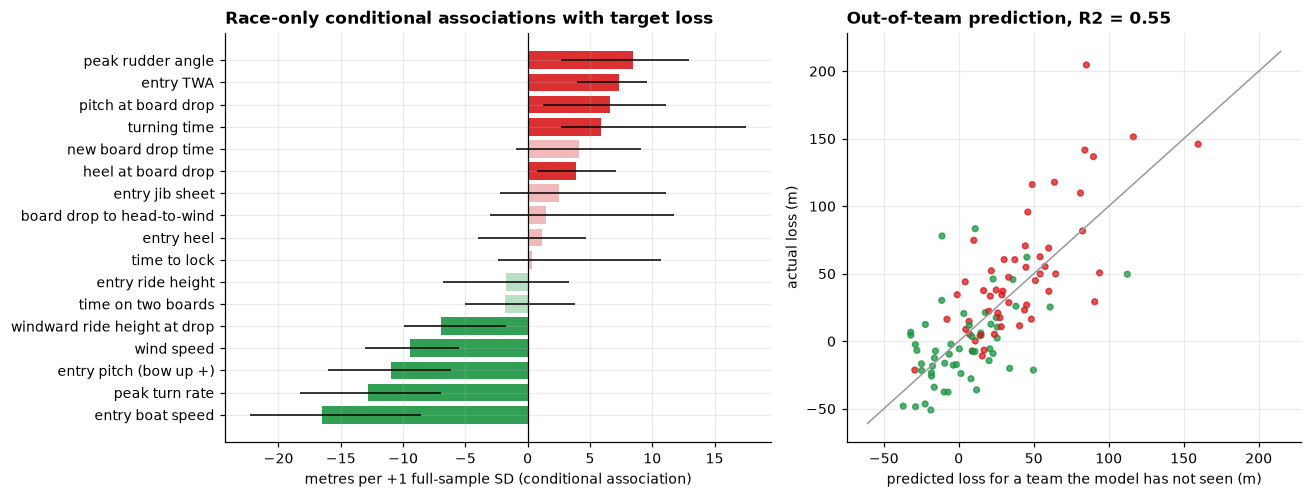

In [28]:
selection = GridSearchCV(ridge(), {"ridge__alpha": np.logspace(-1, 3, 25)},
                         cv=GroupKFold(5), scoring="neg_mean_absolute_error", n_jobs=1)
selection.fit(X, y, groups=groups)
alpha = selection.best_params_["ridge__alpha"]
fixed_scale = selection.best_estimator_["standardscaler"].scale_
rng = np.random.default_rng(0)
boats = groups.unique()
coefs = []
for _ in range(300):                                   # bootstrap whole teams, not single tacks
    pick = rng.choice(boats, size=len(boats), replace=True)
    idx = np.concatenate([np.flatnonzero(groups.to_numpy() == b) for b in pick])
    model = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=alpha)).fit(X.iloc[idx], y.iloc[idx])
    coefs.append(model[-1].coef_ / model[1].scale_ * fixed_scale)
coefs = pd.DataFrame(coefs, columns=[FEATURES[c] for c in FEATURES])
summary = pd.DataFrame({"median": coefs.median(), "lo": coefs.quantile(0.05), "hi": coefs.quantile(0.95)}).sort_values("median")
summary = summary.drop(FEATURES["prestart"])  # constant in the race-only population
solid = (summary["lo"] > 0) | (summary["hi"] < 0)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), gridspec_kw={"width_ratios": [1.2, 1]})
ax = axes[0]
ypos = np.arange(len(summary))
colours = np.where(summary["median"] < 0, "#1a9641", "#d7191c")
for keep, alpha in [(solid.to_numpy(), 0.9), (~solid.to_numpy(), 0.3)]:
    ax.barh(ypos[keep], summary["median"].to_numpy()[keep], color=colours[keep], alpha=alpha)
ax.hlines(ypos, summary["lo"], summary["hi"], color="k", lw=1)
ax.set_yticks(ypos, summary.index)
ax.axvline(0, color="k", lw=0.8)
ax.set_xlabel("metres per +1 full-sample SD (conditional association)")
ax.set_title("Race-only conditional associations with target loss")
ax = axes[1]
ax.scatter(pred, y, c=tacks["flying"].map({1: "#1a9641", 0: "#d7191c"}), s=14, alpha=0.75)
lim = [y.min() - 10, y.max() + 10]
ax.plot(lim, lim, color="0.6", lw=1)
ax.set_xlabel("predicted loss for a team the model has not seen (m)")
ax.set_ylabel("actual loss (m)")
ax.set_title(f"Out-of-team prediction, R2 = {r2_score(y, pred):.2f}")
plt.tight_layout()
summary[solid].round(1)

Bars are whole-team bootstrap medians with pointwise 90% intervals. Every resample refits
imputation/scaling and Ridge; regularisation is fixed at the grouped-selected alpha. Coefficients
are rescaled to one fixed full-sample SD, so the physical increment is comparable across draws.
These intervals are conditional on model selection, use only ten team clusters, and do not establish
causal effects. Zero-crossing intervals are inconclusive. The following tertiles are descriptive.


In [29]:
def thirds(col, label, fmt):
    q = pd.qcut(tacks[col], 3)
    out = tacks.groupby(q, observed=True).agg(tacks=("flying", "size"), stayed_flying=("flying", "mean"), loss_m=("loss_vs_targ_vmg", "median"))
    out.index = [f"{label} {fmt.format(i.left)} to {fmt.format(i.right)}" for i in out.index]
    return out


levers = pd.concat([thirds("entry_bsp", "entry speed (km/h)", "{:.0f}"), thirds("max_yaw_rate", "peak turn rate (deg/s)", "{:.0f}"), thirds("entry_rh", "entry ride height (mm)", "{:.0f}")])
levers["stayed_flying"] = (100 * levers["stayed_flying"]).round(0).astype(int).astype(str) + " %"
levers.round(0)

,tacks,stayed_flying,loss_m
entry speed (km/h) 33 to 55,36,28 %,46.0
entry speed (km/h) 55 to 58,35,46 %,9.0
entry speed (km/h) 58 to 73,36,78 %,-6.0
peak turn rate (deg/s) 11 to 29,36,33 %,37.0
peak turn rate (deg/s) 29 to 33,35,63 %,2.0
peak turn rate (deg/s) 33 to 41,36,56 %,8.0
entry ride height (mm) 207 to 901,35,43 %,27.0
entry ride height (mm) 901 to 998,34,59 %,6.0
entry ride height (mm) 998 to 1210,35,54 %,11.0


In [30]:
team = tacks.groupby("BOAT").agg(tacks=("flying", "size"), stayed_flying=("flying", "mean"), loss_m=("loss_vs_targ_vmg", "median"), entry_speed=("entry_bsp", "median"),
                                 turn_rate=("max_yaw_rate", "median"), entry_ride_height=("entry_rh", "median")).sort_values("loss_m")
team["stayed_flying"] = (100 * team["stayed_flying"]).round(0)
team.round(1)

,tacks,stayed_flying,loss_m,entry_speed,turn_rate,entry_ride_height
BOAT,,,,,,
ESP,10,80.0,-11.0,58.8,31.3,950.6
AUS,12,75.0,-8.1,58.2,30.4,995.2
GBR,11,73.0,-2.3,55.8,29.7,978.4
DEN,11,55.0,5.2,57.9,33.4,902.8
GER,10,50.0,13.2,57.2,35.2,916.6
NZL,12,50.0,23.9,55.2,35.4,901.8
SUI,12,33.0,24.3,53.9,27.2,1002.2
USA,9,0.0,26.9,53.3,30.8,879.2
BRA,9,33.0,28.6,55.6,29.1,970.1


**Interpretation and limits**

The race-only tables describe associations between entry conditions, the subsequent turn and a
40 s target-loss benchmark. Flight-state groups differ, but that alone does not establish the
counterfactual cost of coming down. Entry speed, ride height and turn dynamics are correlated.

The validation table is the appropriate performance claim: it distinguishes full retrospective,
entry-only and pooled populations. Pre-start losses differ materially, and pooled scores should
not be presented as racing-only predictive skill. An 18-feature model's R² does not belong to just
two features. Further nonlinear baselines and different days would test robustness.

Tertile differences do not prove an optimal turn-rate threshold or that forcing a faster turn helps.
Coefficients suggest hypotheses for controlled trials, not guaranteed crew actions. Inconclusive
timing/jib/ride-height coefficients do not establish absence of an effect.


## Question 8 — descriptive race differences

Each inferred finish gap is split into the start crossing difference and interpolated leg-duration
differences. Leg distances are integrated over exactly those same intervals, including transition
fractions. A logarithmic-mean accounting allocation separates distance and speed contributions;
their sum is checked against the leg gaps. This is one convention, not a causal identification of
why speed or distance differed. Components can be negative, including offsetting equal-time cases.


In [31]:
results, gaps, splits, starts, summaries = {}, {}, {}, {}, {}
for rid in RACES:
    times = race.leg_times(metrics[rid], courses[rid])
    gaps[rid] = race.gap_to_winner(times)
    summaries[rid] = race.leg_summary(metrics[rid], courses[rid])
    splits[rid] = race.distance_speed_split(summaries[rid], gaps[rid].index[0])
    starts[rid] = race.start_table(metrics[rid], courses[rid])
    results[rid] = gaps[rid]["total"]
    for boat in gaps[rid].index:
        actual = splits[rid].loc[boat][["further_s", "slower_s"]].sum().sum()
        expected = gaps[rid].loc[boat].drop(["start", "total"]).sum()
        np.testing.assert_allclose(actual, expected, atol=1e-5)
order = pd.DataFrame({rid: pd.Series(range(1, len(results[rid]) + 1), index=results[rid].index) for rid in RACES})
board = pd.concat({"finish position": order, "seconds behind the winner": pd.DataFrame(results)}, axis=1)
board = board.reindex(order[RACES[:3]].sum(axis=1, skipna=False).sort_values().index)
display(board.round(1))
display(pd.DataFrame({rid: pd.Series(times.attrs["finish_status"])
                      for rid in RACES
                      for times in [race.leg_times(metrics[rid], courses[rid])]}))

finish position                            seconds behind the winner                           
            25011905 25011906 25011907 25011908                  25011905 25011906 25011907 25011908
BOAT                                                                                                
DEN                8        1      1.0      NaN                      57.8      0.0      0.0      NaN
ESP                5        3      3.0      2.0                      34.9     11.1     40.8     23.0
GBR                2        4      6.0      3.0                      10.2     23.6     64.0     37.1
NZL                4        6      2.0      NaN                      33.9     35.0     32.3      NaN
GER                6        7      5.0      NaN                      42.4     39.9     56.8      NaN
BRA                7        5      7.0      NaN                      53.3     29.4     83.6      NaN
ITA                3        9      8.0      NaN                      26.5     49.7     87.4      NaN
SUI               10       10      4.0      NaN                      96.9     60.6     48.8      NaN
USA                9        8      9.0      NaN                      75.2     42.3     88.4      NaN
AUS                1        2      NaN      1.0                       0.0     10.4      NaN      0.0

,25011905,25011906,25011907,25011908
AUS,estimated,estimated,incomplete,observed
BRA,estimated,estimated,estimated,NaN
CAN,incomplete,incomplete,incomplete,NaN
DEN,estimated,estimated,estimated,NaN
ESP,observed,estimated,estimated,observed
GBR,estimated,estimated,estimated,estimated
GER,estimated,estimated,estimated,NaN
ITA,observed,estimated,observed,NaN
NZL,estimated,estimated,estimated,NaN
SUI,observed,estimated,estimated,NaN


AUS's race-7 log ends near the first windward gate; its finish is unavailable here, which
does not by itself prove official DNF. Canada has no detected start. The next table identifies
observed versus short-extrapolated finish timings; estimated timing is not an official result.


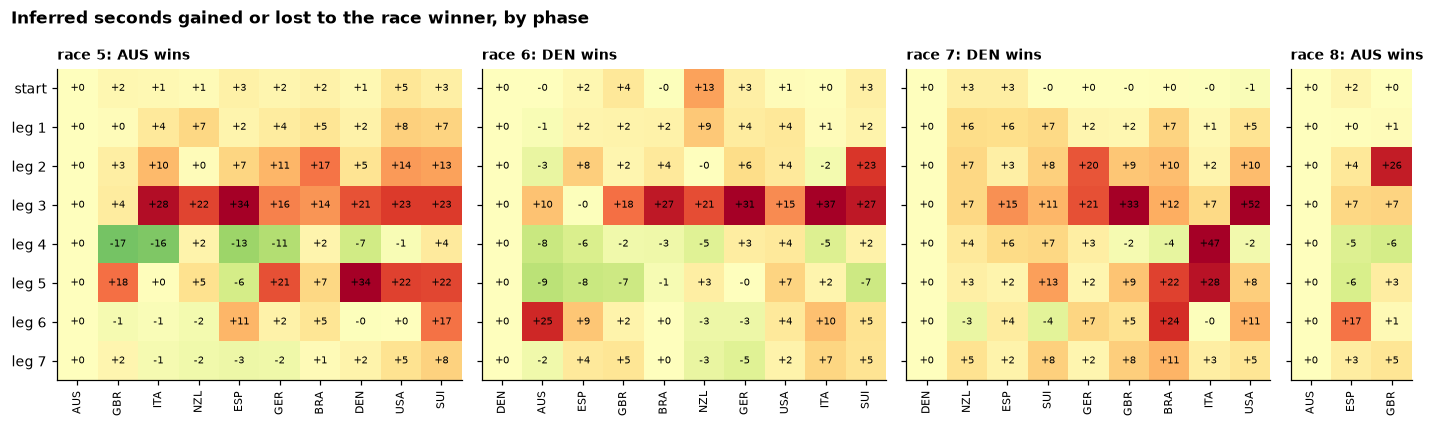

In [32]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.9), gridspec_kw={"width_ratios": [10, 10, 9, 3]})
for ax, rid in zip(axes, RACES):
    g = gaps[rid].drop(columns="total")
    im = ax.imshow(g.to_numpy().T, cmap="RdYlGn_r", vmin=-30, vmax=30, aspect="auto")
    ax.set_xticks(range(len(g)), g.index, rotation=90, fontsize=7)
    ax.set_yticks(range(g.shape[1]), g.columns if ax is axes[0] else [""] * g.shape[1])
    for (i, j), v in np.ndenumerate(g.to_numpy()):
        ax.text(i, j, f"{v:+.0f}", ha="center", va="center", fontsize=6.5)
    ax.set_title(f"race {rid % 100}: {g.index[0]} wins", fontsize=9)
    ax.grid(False)
fig.suptitle("Inferred seconds gained or lost to the race winner, by phase", x=0.01, ha="left", fontweight="bold", fontsize=11)
plt.tight_layout()

In [33]:
phase = pd.concat({rid: g.drop(columns="total").iloc[1:] for rid, g in gaps.items()})
share = phase.clip(lower=0).sum() / phase.clip(lower=0).sum().sum()
how = pd.concat({rid: s.groupby("BOAT")[["further_s", "slower_s"]].sum().reindex(gaps[rid].index[1:]) for rid, s in splits.items()})
off = pd.concat({rid: s["off_foil_s"].drop("USA", level="BOAT", errors="ignore").groupby("BOAT").sum() for rid, s in summaries.items()})
both = pd.concat([how.drop("USA", level=1, errors="ignore").sum(axis=1).rename("gap"), off.rename("off_foil")], axis=1).dropna()
print("Share of gross positive phase losses (gains clipped), by phase:", ", ".join(f"{k} {v:.0%}" for k, v in share.items()))
print(f"Logarithmic allocation to distance: {how['further_s'].sum():.0f} s, to speed: {how['slower_s'].sum():.0f} s  (all non-winning finishers, all races)")
print(f"Correlation between seconds off the foils and seconds lost on the legs: {both['gap'].corr(both['off_foil']):.2f}  (USA left out: ride height sensor)")

Share of gross positive phase losses (gains clipped), by phase: start 4%, leg 1 7%, leg 2 15%, leg 3 36%, leg 4 6%, leg 5 15%, leg 6 11%, leg 7 6%
Logarithmic allocation to distance: 339 s, to speed: 905 s  (all non-winning finishers, all races)
Correlation between seconds off the foils and seconds lost on the legs: 0.53  (USA left out: ride height sensor)


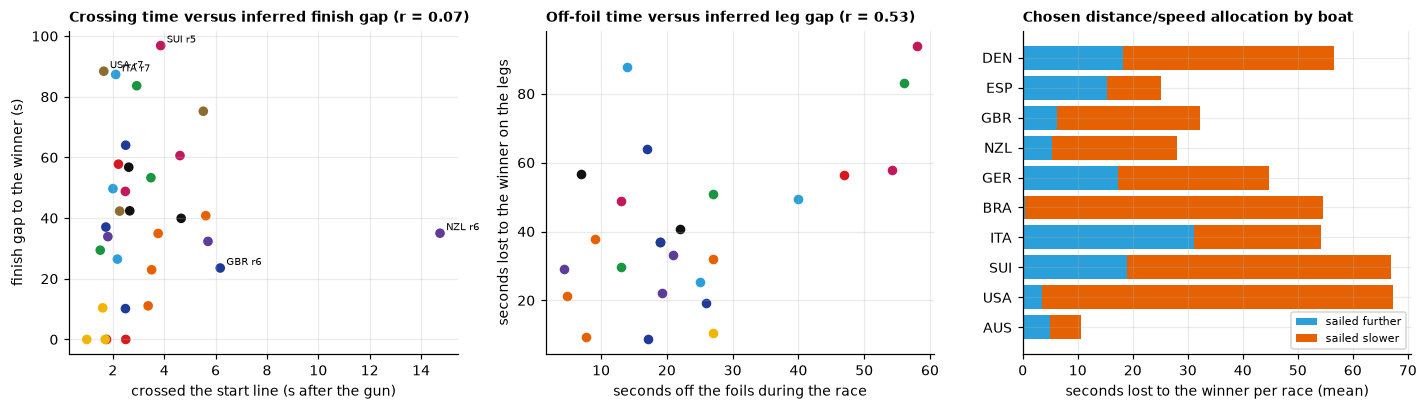

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
ax = axes[0]
for rid in RACES:
    s = starts[rid].join(gaps[rid]["total"])
    ax.scatter(s["cross_s"], s["total"], c=[C[b] for b in s.index], s=28)
    for b, r in s.iterrows():
        if r["cross_s"] >= 6 or r["total"] > 85:
            ax.annotate(f"{b} r{rid % 100}", (r["cross_s"], r["total"]), fontsize=6.5, xytext=(4, 2), textcoords="offset points")
ax.set_xlabel("crossed the start line (s after the gun)")
ax.set_ylabel("finish gap to the winner (s)")
late = pd.concat({rid: starts[rid].join(gaps[rid]["total"]) for rid in RACES}).dropna()
ax.set_title(f"Crossing time versus inferred finish gap (r = {late['cross_s'].corr(late['total']):.2f})", fontsize=9)

ax = axes[1]
for (rid, boat), r in both.iterrows():
    ax.scatter(r["off_foil"], r["gap"], color=C[boat], s=28)
ax.set_xlabel("seconds off the foils during the race")
ax.set_ylabel("seconds lost to the winner on the legs")
ax.set_title(f"Off-foil time versus inferred leg gap (r = {both['gap'].corr(both['off_foil']):.2f})", fontsize=9)

ax = axes[2]
h = how.groupby(level=1).mean().reindex(board.index).dropna()
ax.barh(h.index, h["further_s"], color="#2b9fd9", label="sailed further")
ax.barh(h.index, h["slower_s"], left=h["further_s"].clip(lower=0), color="#e66101", label="sailed slower")
ax.invert_yaxis()
ax.set_xlabel("seconds lost to the winner per race (mean)")
ax.set_title("Chosen distance/speed allocation by boat", fontsize=9)
ax.legend(fontsize=7)
plt.tight_layout()

In [35]:
rid = 25011905
tbl = starts[rid].join(gaps[rid][["leg 1", "leg 2", "leg 3", "total"]]).join(summaries[rid]["off_foil_s"].groupby("BOAT").sum().rename("off_foil_s"))
tbl = tbl.join(man[(man["race"] == rid) & man["leg"].between(1, 7)].groupby("BOAT").size().rename("manoeuvres")).sort_values("total")
print("Race 5 in numbers")
tbl.round(0)

Race 5 in numbers


,at_gun_behind_line_m,at_gun_speed_kmh,cross_s,cross_speed_kmh,leg 1,leg 2,leg 3,total,off_foil_s,manoeuvres
BOAT,,,,,,,,,,
AUS,22.0,80.0,1.0,80.0,0.0,0.0,0.0,0.0,10.0,7
GBR,48.0,66.0,2.0,77.0,0.0,3.0,4.0,10.0,17.0,8
ITA,43.0,68.0,2.0,76.0,4.0,10.0,28.0,26.0,25.0,9
NZL,13.0,30.0,2.0,36.0,7.0,0.0,22.0,34.0,21.0,7
ESP,77.0,71.0,4.0,79.0,2.0,7.0,34.0,35.0,27.0,8
GER,39.0,49.0,3.0,62.0,4.0,11.0,16.0,42.0,22.0,8
BRA,48.0,49.0,3.0,61.0,5.0,17.0,14.0,53.0,27.0,7
DEN,38.0,61.0,2.0,67.0,2.0,5.0,21.0,58.0,47.0,9
USA,68.0,40.0,6.0,55.0,8.0,14.0,23.0,75.0,17.0,6


### Interpretation

The phase table and race-5 detail identify where each boat gained or lost time relative to the
inferred winner. They support descriptive event investigation, not a complete causal explanation
of winning. AUS ranks first in races 5/8 and DEN in 6/7 under the stated timing convention.

Leg 3 contributes the largest gross positive phase-loss share in this sample. That denominator
clips gains: it is different from the net sum of finish deficits. Leg length/duration, traffic,
tacks and local wind conditions are competing explanations and should be examined together.

The crossing-time correlation pools 32 finishes with repeated teams across races; it does not
show that starts are strategically unimportant. Crossing position/speed and traffic are omitted.
The off-foil correlation excludes USA and relies on an operational 300 mm aggregation threshold,
different from the manoeuvre summary's 400 mm turn-minimum flag.

The distance/speed bars are an exact allocation of these internally consistent estimated durations,
not independently identified causes. A longer route can itself alter speed and wind exposure.
Near-line finish extrapolation, antenna position, gate tolerance and sensor aggregation remain
sources of uncertainty. These are findings from one afternoon, not rankings of intrinsic team skill.
